1) P(snake eyes) = 0.027777777777777776  P(seven) = 0.16666666666666666  ratio seven/snake = 6.0

2) sum, probability (convolution, counts/36):
   2 1 / 36
   3 2 / 36
   4 3 / 36
   5 4 / 36
   6 5 / 36
   7 6 / 36
   8 5 / 36
   9 4 / 36
   10 3 / 36
   11 2 / 36
   12 1 / 36


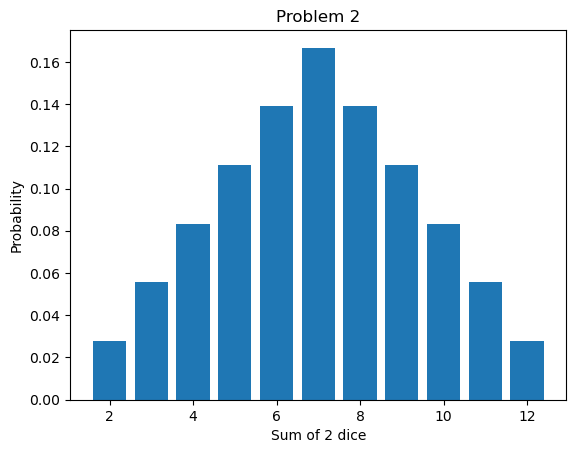


3) mean = 6.999999999999998  variance = 5.833333333333333  (expected 7 and 35/6 = 5.833333333333333 )

4) mean of average = 3.4999999999999982  std of average = 0.5400617248673215  sigma/sqrt(10) = 0.5400617248673216


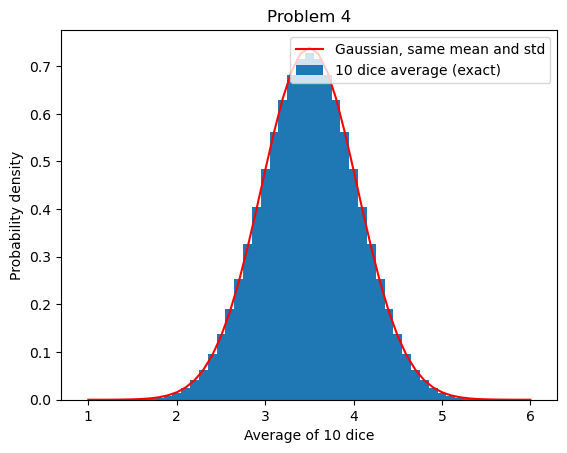


5) sum of 2 Gaussians: mean = -6.2519234234059695e-12  std = 1.414213562372653  sqrt(2)*sigma = 1.4142135623730951
   max difference from a Gaussian with that std: 1.322830733840874e-13
   N = 1  std of sum = 1.0  std of average = 1.0
   N = 4  std of sum = 2.0  std of average = 0.5
   N = 16  std of sum = 4.0  std of average = 0.25
   N = 100  std of sum = 10.0  std of average = 0.1


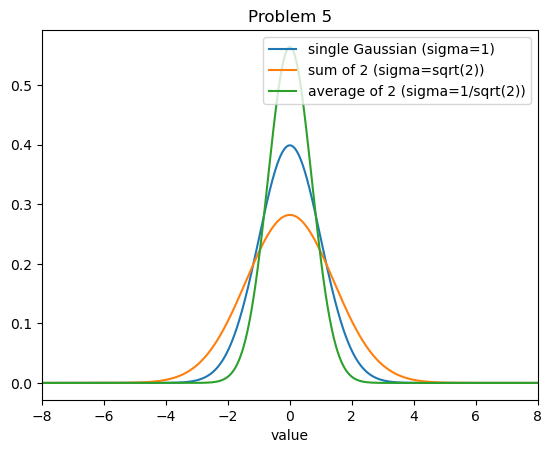

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Problem 1: snake eyes vs seven
rolls = [(a, b) for a in range(1, 7) for b in range(1, 7)]   # all 36 outcomes
p_snake = sum(1 for a, b in rolls if a + b == 2) / 36
p_seven = sum(1 for a, b in rolls if a + b == 7) / 36
print("1) P(snake eyes) =", p_snake, " P(seven) =", p_seven, " ratio seven/snake =", p_seven / p_snake)

# Problem 2: sum of 2 dice via convolution
die = np.ones(6) / 6                  # P(1..6) = 1/6 each
two_dice = np.convolve(die, die)      # length 11
# np.convolve index 0 means the smallest sum (1+1 = 2), so shift the x-axis by 2
x2 = np.arange(2, 13)
print("\n2) sum, probability (convolution, counts/36):")
for s, p in zip(x2, two_dice):
    print("  ", s, round(p * 36), "/ 36")

plt.figure()
plt.bar(x2, two_dice)
plt.xlabel("Sum of 2 dice")
plt.ylabel("Probability")
plt.title("Problem 2")
plt.show()

# Problem 3: mean and variance
mean = np.sum(x2 * two_dice)
var = np.sum((x2 - mean) ** 2 * two_dice)
print("\n3) mean =", mean, " variance =", var, " (expected 7 and 35/6 =", 35 / 6, ")")

# Problem 4: average of 10 dice
dist = die
for i in range(9):                    # 9 more convolutions -> 10 dice
    dist = np.convolve(dist, die)
x10_sum = np.arange(10, 61)           # sums run from 10 to 60
x10_avg = x10_sum / 10                # average = sum / 10
bin_width = 0.1
pdf = dist / bin_width                # turn probability per bin into a density

mu = 3.5
sd = np.sqrt(35 / 12 / 10)            # sigma_die / sqrt(10)
gauss = np.exp(-(x10_avg - mu) ** 2 / (2 * sd ** 2)) / (sd * np.sqrt(2 * np.pi))

print("\n4) mean of average =", np.sum(x10_avg * dist), " std of average =", np.sqrt(np.sum((x10_avg - mu) ** 2 * dist)), " sigma/sqrt(10) =", sd)

plt.figure()
plt.bar(x10_avg, pdf, width=bin_width, label="10 dice average (exact)")
plt.plot(x10_avg, gauss, "r", label="Gaussian, same mean and std")
plt.xlabel("Average of 10 dice")
plt.ylabel("Probability density")
plt.legend()
plt.title("Problem 4")
plt.show()

# Problem 5: sum and average of Gaussians
dx = 0.01
x = np.arange(-20, 20, dx)
mu1, sigma1 = 0.0, 1.0

def gaussian(x, mu, sigma):
    return np.exp(-(x - mu) ** 2 / (2 * sigma ** 2)) / (sigma * np.sqrt(2 * np.pi))

g = gaussian(x, mu1, sigma1)
g_sum = np.convolve(g, g) * dx                 # density of the sum of 2 Gaussians
x_sum = np.arange(len(g_sum)) * dx + 2 * x[0]  # correct x-axis for the convolution

m = np.sum(x_sum * g_sum) * dx
s = np.sqrt(np.sum((x_sum - m) ** 2 * g_sum) * dx)
print("\n5) sum of 2 Gaussians: mean =", m, " std =", s, " sqrt(2)*sigma =", np.sqrt(2) * sigma1)
print("   max difference from a Gaussian with that std:", np.max(np.abs(g_sum - gaussian(x_sum, m, s))))

# average of N Gaussians has std sigma/sqrt(N)
for N in [1, 4, 16, 100]:
    print("   N =", N, " std of sum =", sigma1 * np.sqrt(N), " std of average =", sigma1 / np.sqrt(N))

plt.figure()
plt.plot(x, g, label="single Gaussian (sigma=1)")
plt.plot(x_sum, g_sum, label="sum of 2 (sigma=sqrt(2))")
plt.plot(x_sum * 0.5, g_sum * 2, label="average of 2 (sigma=1/sqrt(2))")
plt.xlim(-8, 8)
plt.legend()
plt.xlabel("value")
plt.title("Problem 5")
plt.show()

# Problem 1: 
Rolling seven is six times more likely than rolling snake eyes (6/36 vs 1/36)

# Problem 2: 
Probabilities of the sum of two dice by counting: 2: (1,1) --> 1/36 3: (2,1) , (1,2) --> 2/36 4: (2,2),(3,1),(1,3) --> 3/36 5: (2,3),(3,2),(1,4),(4,1) --> 4/36 6: (1,5),(5,1),(4,2),(2,4),(3,3) --> 5/36 7: (1,6),(6,1),(2,5),(5,2),(4,3),(3,4) --> 6/36 With symmetry we know that 8 through 12 will match the probabilities of 1 through 6 8: 5/36 9: 4/36 10: 3/36 11: 2/36 12: 1/36

# Problem 3:
The mean is 7 and the variance is 35/6 ≈ 5.83. This matches 2 * 3.5 for the mean and 2 × 35/12 for the variance, since variances of independent dice add.

# Problem 4: 
Average of 10 dice. The sum runs from 10 to 60, so the average runs from 1.0 to 6.0 in steps of 0.1. The mean is 3.5 and the standard deviation is sqrt(35/12)/sqrt(10) = 0.540, which is confirmed above. The histogram is divided by the bin width so it is a density comparable to the Gaussian curve.

Is it Gaussian? It is approximately Gaussian (central limit theorem), and the overlay is very close. It is not exactly Gaussian, since the tails end at 1 and 6 whereas a Gaussian distribution would have tails going past these values

# Problem 5:
Gaussian sums and averages. The numerical convolution of two N(0,1) Gaussians gives a Gaussian with σ = 1.41421 = sqrt(2) So:

The sum of N Gaussians has standard deviation σsqrt(N).
The average of N Gaussians has standard deviation σ/sqrt(N).

For integrating a signal over time, the signal grows like N while the noise grows like sqrt(N), so the signal-to-noise ratio improves as sqrt(N). This is why error propagation with Gaussian errors works: independent errors add as the root sum of squares sqrt(σ^2+), and averaging N measurements reduces the uncertainty by 1/sqrt(N).